# Black-Ball Detection and Visual Tracking

A black target on a white background uses grayscale inverse thresholding to construct the mask. Contour validation, centroid estimation, apparent-size error, and differential-drive control follow the same structure used for color tracking.


In [1]:
from pathlib import Path
from math import pi
import importlib.util

import cv2
import matplotlib.pyplot as plt

SEARCH_LOCATIONS = [
    Path.cwd(),
    Path.cwd() / "Codigos_curso" / "ENG",
]
BASE_DIR = next(
    (location for location in SEARCH_LOCATIONS
     if (location / "black_ball_tracking.py").is_file()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError(
        "black_ball_tracking.py was not found. Keep the script next to "
        "the notebook or run the notebook from the course repository root."
    )

MODULE_PATH = BASE_DIR / "black_ball_tracking.py"
spec = importlib.util.spec_from_file_location("black_ball_tracking", MODULE_PATH)
tracker = importlib.util.module_from_spec(spec)
spec.loader.exec_module(tracker)

compute_control = tracker.compute_control
detect_ball = tracker.detect_ball
draw_result = tracker.draw_result
process_frame = tracker.process_frame
segment_black = tracker.segment_black

IMAGE_PATH = BASE_DIR / "imagenes" / "black_ball_reference.png"


## Segmentation

For grayscale intensity $I(x,y)$ and threshold $T$, inverse thresholding produces

$$
M(x,y)=
\begin{cases}
255, & I(x,y)\leq T,\\
0, & I(x,y)>T.
\end{cases}
$$

Opening removes isolated foreground pixels, and closing fills small holes. This function replaces HSV segmentation; the remaining detection and control stages are unchanged.


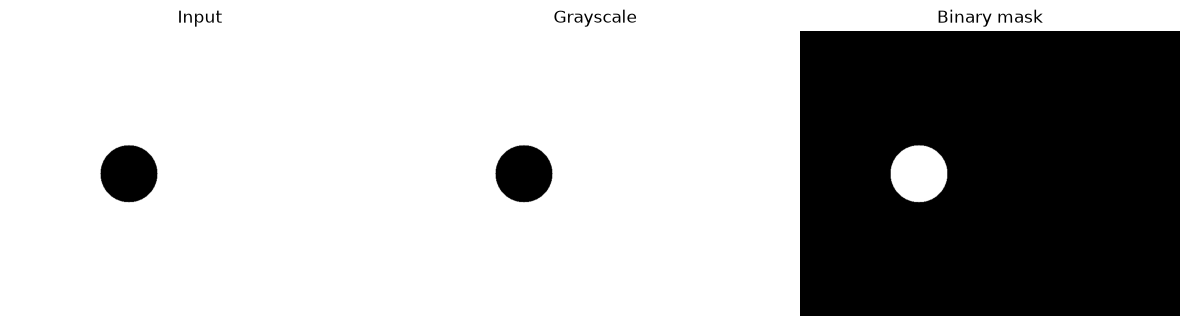

In [2]:
image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH.resolve()}")

gray, mask, detection, control = process_frame(image)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale")
axes[2].imshow(mask, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Binary mask")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()


## Contour measurements

Circularity and solidity are

$$
C=\frac{4\pi A}{P^2},
\qquad
S=\frac{A}{A_h},
$$

where $A$ is contour area, $P$ is perimeter, and $A_h$ is convex-hull area.


In [3]:
if detection is None:
    raise RuntimeError("No valid ball was detected.")

contour, center, radius = detection
area = cv2.contourArea(contour)
perimeter = cv2.arcLength(contour, True)
hull_area = cv2.contourArea(cv2.convexHull(contour))
circularity = 4.0 * pi * area / (perimeter * perimeter)
solidity = area / hull_area

print(f"center      = {center} px")
print(f"radius      = {radius:.4f} px")
print(f"area        = {area:.4f} px^2")
print(f"perimeter   = {perimeter:.4f} px")
print(f"circularity = {circularity:.4f}")
print(f"solidity    = {solidity:.4f}")


center      = (250, 300) px
radius      = 60.0001 px
area        = 11118.0000 px^2
perimeter   = 393.9899 px
circularity = 0.9000
solidity    = 0.9916


## Visual errors and wheel commands

The normalized errors are

$$
e_x=\frac{c_x-W/2}{W/2},
\qquad
e_r=r_d-\frac{r}{H}.
$$

$(c_x,c_y)$ is the centroid, $r$ is the enclosing-circle radius, $W\times H$ is the image resolution, and $r_d$ is the desired radius-to-height ratio. The differential-drive commands are $\omega_L=v+\omega$ and $\omega_R=v-\omega$.


e_x = -0.3750
e_r = +0.0700
left wheel  = +0.3441 rad/s
right wheel = +2.7441 rad/s


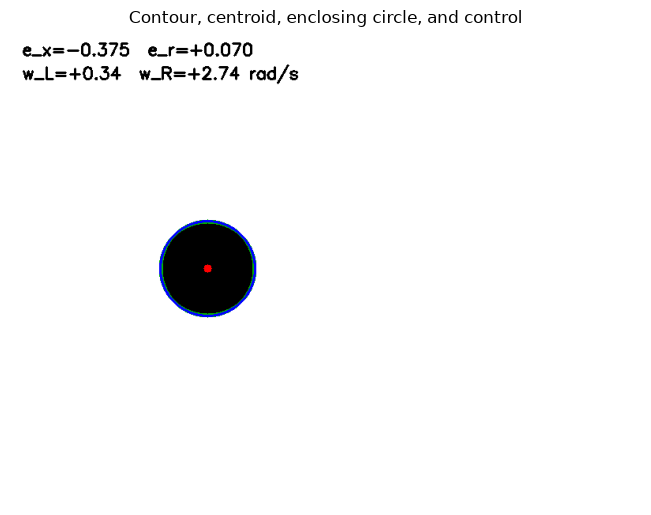

In [4]:
left, right, error_x, error_radius = control
print(f"e_x = {error_x:+.4f}")
print(f"e_r = {error_radius:+.4f}")
print(f"left wheel  = {left:+.4f} rad/s")
print(f"right wheel = {right:+.4f} rad/s")

result = draw_result(image, detection, control)
plt.figure(figsize=(7, 5.25))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Contour, centroid, enclosing circle, and control")
plt.axis("off")
plt.tight_layout()
plt.show()
